# 03 | Budget Optimization & Cost Control

## Business Questions

This analysis evaluates project and departmental budget performance to identify financial risks and opportunities for cost optimization.

1. **Budget Performance:** Which projects and departments exceed their planned budgets?
2. **Financial Impact:** What are the absolute and percentage budget variances, and how do they affect overall spending?
3. **Cost Drivers:** Which cost categories contribute most to budget overruns?
4. **Management Priorities:** Which departments and expense categories should be prioritized for financial review?
5. **Business Improvement:** What corrective actions could strengthen cost control, budget accountability, and forecasting accuracy?

**Business Objective:** Identify unfavorable budget variances, prioritize financial risks, and recommend actionable improvements to support efficient resource allocation.


In [ ]:
from pathlib import Path
import os
import sys
import subprocess

# 01 | GitHub repository
REPOSITORY_URL = (
    "https://github.com/MayerAnnamaria/python-business-analytics-project.git"
)

# 02 | Local project directory
PROJECT_DIR = Path("/content/python-business-analytics-project")

# 03 | Clone repository if it does not exist
if not PROJECT_DIR.exists():
    subprocess.run(
        ["git", "clone", REPOSITORY_URL, str(PROJECT_DIR)],
        check=True
    )

# 04 | Install project dependencies
%pip install "pandas>=2.0,<3.0" "numpy>=1.24,<3.0" "matplotlib>=3.7,<4.0" "openpyxl>=3.1,<4.0" "pytest>=7,<10"


# 05 | Set working directory
os.chdir(PROJECT_DIR)

if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

# 06 | Configure input and output folders
INPUT_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
import matplotlib.pyplot as plt
from src.business_analytics.io import read_sources
from src.business_analytics.cleaning import clean_sources
from src.business_analytics.budget import budget_analysis
tables=clean_sources(read_sources(INPUT_DIR))
category, projects=budget_analysis(tables)
display(projects[['project_id','department','planned_budget','actual_cost','variance','variance_pct','budget_status']].head(12))
print('Over-budget projects:',int(projects['variance'].gt(0).sum()))
print('Total planned:',round(projects['planned_budget'].sum(),2),' Total actual:',round(projects['actual_cost'].sum(),2))


,project_id,department,planned_budget,actual_cost,variance,variance_pct,budget_status
21,PRJ-022,Customer Service,118600,130980.00,12380.00,10.4,Over budget
10,PRJ-011,Marketing,83000,93752.52,10752.52,13.0,Over budget
19,PRJ-020,Operations,112100,122040.00,9940.00,8.9,Over budget
15,PRJ-016,Customer Service,99300,107177.52,7877.52,7.9,Over budget
4,PRJ-005,Marketing,63600,70245.00,6645.00,10.4,Over budget
20,PRJ-021,Finance,115300,121802.49,6502.49,5.6,Over budget
13,PRJ-014,Operations,92700,98607.48,5907.48,6.4,Over budget
2,PRJ-003,Finance,57100,62160.00,5060.00,8.9,Over budget
9,PRJ-010,Customer Service,79800,84150.00,4350.00,5.5,Over budget
3,PRJ-004,Customer Service,60400,63792.51,3392.51,5.6,Over budget


Over-budget projects: 15
Total planned: 2108900  Total actual: 2155500.03


,cost_category,planned_budget,actual_cost,variance
1,Labor,1110000,1129325.01,19325.01
2,Software,532800,550200.00,17400.00
0,External Services,332900,339045.00,6145.00
3,Training,133200,136930.02,3730.02


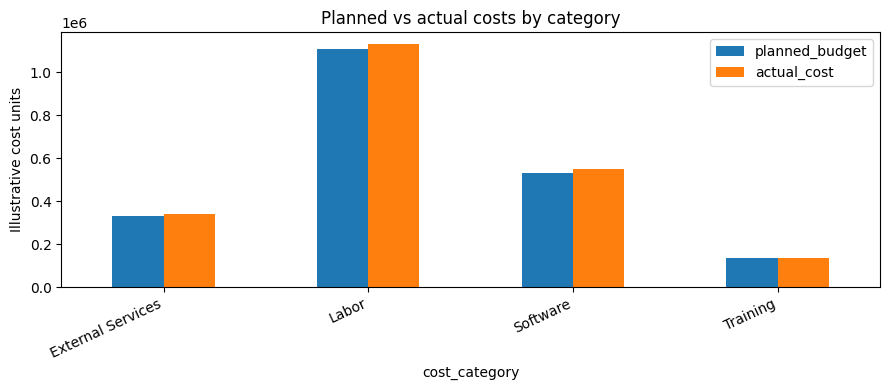

,department,planned_budget,actual_cost,variance
0,Customer Service,358100,386100.03,28000.03
5,Operations,332000,351409.98,19409.98
1,Finance,344900,359967.48,15067.48
4,Marketing,370900,375822.51,4922.51
3,IT,319200,314020.02,-5179.98
2,HR,383800,368180.01,-15619.99


In [4]:
# Identify the largest budget variances by cost category and visualize planned versus actual spending.
drivers = category.groupby('cost_category', as_index=False)[['planned_budget', 'actual_cost', 'variance']].sum()
display(drivers.sort_values('variance', ascending=False))

ax = drivers.set_index('cost_category')[['planned_budget', 'actual_cost']].plot(kind='bar', figsize=(9, 4), title='Planned vs actual costs by category')
ax.set_ylabel('Illustrative cost units')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

# Compare planned budgets, actual costs, and spending variances across departments to identify potential cost overruns.
by_department = projects.groupby('department', as_index=False)[['planned_budget', 'actual_cost', 'variance']].sum()
display(by_department.sort_values('variance', ascending=False))

In [5]:

# =============================================================================
# 04 | DEPARTMENT BUDGET PERFORMANCE & BUSINESS RECOMMENDATIONS
# =============================================================================
# Objective:
# Evaluate department-level budget performance, identify financial risks,
# and recommend management actions based on the variance results.
# =============================================================================

import pandas as pd

# 01 | Aggregate budget performance by department
department_analysis = (
    projects.groupby("department", as_index=False)[
        ["planned_budget", "actual_cost"]
    ]
    .sum()
)

# 02 | Calculate absolute and percentage budget variance
department_analysis["variance"] = (
    department_analysis["actual_cost"]
    - department_analysis["planned_budget"]
)

department_analysis["variance_pct"] = (
    department_analysis["variance"]
    / department_analysis["planned_budget"].replace(0, float("nan"))
    * 100
).round(2)

# 03 | Classify budget performance
def interpret_variance(row):
    if pd.isna(row["variance_pct"]):
        return "No approved budget"
    if row["variance"] > 0 and row["variance_pct"] >= 5:
        return "Significant overspend"
    elif row["variance"] > 0:
        return "Minor overspend"
    elif row["variance"] < 0:
        return "Below budget"
    else:
        return "On budget"

department_analysis["interpretation"] = department_analysis.apply(
    interpret_variance,
    axis=1
)

# 04 | Recommend actions based on budget performance
def recommend_action(row):
    status = row["interpretation"]

    if status == "Significant overspend":
        return (
            "High priority: Investigate major cost drivers, "
            "scope changes, and unplanned expenses."
        )
    elif status == "Minor overspend":
        return (
            "Monitor spending and review unfavorable "
            "cost categories."
        )
    elif status == "Below budget":
        return (
            "Review underspending to distinguish actual savings "
            "from delayed activities or unrecorded costs."
        )
    elif status == "On budget":
        return "Maintain regular budget monitoring."
    else:
        return "Review spending without an approved budget."

department_analysis["recommended_action"] = department_analysis.apply(
    recommend_action,
    axis=1
)

# 05 | Sort departments by largest unfavorable variance
department_analysis = department_analysis.sort_values(
    "variance",
    ascending=False
).reset_index(drop=True)

# 06 | Display management report
display(
    department_analysis.style.format({
        "planned_budget": "{:,.2f}",
        "actual_cost": "{:,.2f}",
        "variance": "{:+,.2f}",
        "variance_pct": "{:+.2f}%"
    })
)


,department,planned_budget,actual_cost,variance,variance_pct,interpretation,recommended_action
0,Customer Service,"358,100.00","386,100.03","+28,000.03",+7.82%,Significant overspend,"High priority: Investigate major cost drivers, scope changes, and unplanned expenses."
1,Operations,"332,000.00","351,409.98","+19,409.98",+5.85%,Significant overspend,"High priority: Investigate major cost drivers, scope changes, and unplanned expenses."
2,Finance,"344,900.00","359,967.48","+15,067.48",+4.37%,Minor overspend,Monitor spending and review unfavorable cost categories.
3,Marketing,"370,900.00","375,822.51","+4,922.51",+1.33%,Minor overspend,Monitor spending and review unfavorable cost categories.
4,IT,"319,200.00","314,020.02","-5,179.98",-1.62%,Below budget,Review underspending to distinguish actual savings from delayed activities or unrecorded costs.
5,HR,"383,800.00","368,180.01","-15,619.99",-4.07%,Below budget,Review underspending to distinguish actual savings from delayed activities or unrecorded costs.


In [6]:

# =============================================================================
# 05 | OVERALL BUSINESS IMPACT
# =============================================================================
# Objective:
# Summarize total planned spending, actual costs, and overall
# budget performance across all departments.
# =============================================================================

# 01 | Calculate financial KPIs
total_planned = department_analysis["planned_budget"].sum()
total_actual = department_analysis["actual_cost"].sum()

total_variance = total_actual - total_planned

total_variance_pct = (
    total_variance / total_planned * 100
    if total_planned != 0
    else float("nan")
)

# 02 | Determine overall budget status
if total_variance > 0:
    overall_status = "Over Budget"
elif total_variance < 0:
    overall_status = "Below Budget"
else:
    overall_status = "On Budget"

# 03 | Create executive KPI summary
overall_impact = pd.DataFrame({
    "KPI": [
        "Total Planned Budget",
        "Total Actual Spending",
        "Overall Budget Variance",
        "Overall Variance (%)",
        "Budget Status"
    ],
    "Value": [
        f"{total_planned:,.2f}",
        f"{total_actual:,.2f}",
        f"{total_variance:+,.2f}",
        f"{total_variance_pct:+.2f}%",
        overall_status
    ]
})

display(overall_impact)

# 04 | Display executive interpretation
print("MANAGEMENT SUMMARY")
print("-" * 60)

print(
    f"Across {len(department_analysis)} departments, "
    f"actual spending {'exceeds' if total_variance > 0 else 'is at or below'} "
    f"the planned budget."
)

print(
    f"Overall variance: {total_variance:+,.2f} "
    f"({total_variance_pct:+.2f}%)."
)

print(
    "Recommended action: Prioritize departments with the "
    "largest unfavorable budget variances and investigate "
    "potential cost drivers before implementing corrective measures."
)


,KPI,Value
0,Total Planned Budget,"2,108,900.00"
1,Total Actual Spending,"2,155,500.03"
2,Overall Budget Variance,"+46,600.03"
3,Overall Variance (%),+2.21%
4,Budget Status,Over Budget


MANAGEMENT SUMMARY
------------------------------------------------------------
Across 6 departments, actual spending exceeds the planned budget.
Overall variance: +46,600.03 (+2.21%).
Recommended action: Prioritize departments with the largest unfavorable budget variances and investigate potential cost drivers before implementing corrective measures.


In [7]:

# =============================================================================
# 06 | COST CATEGORY ANALYSIS & BUSINESS FINDINGS
# =============================================================================
# Identify cost categories driving budget overruns, calculate absolute
# and percentage variances, and prioritize management investigations.
# =============================================================================

import pandas as pd

# 01 | Link cost categories to departments
category_details = category.merge(
    tables["projects"][["project_id", "department"]],
    on="project_id",
    how="left",
    validate="many_to_one"
)

# 02 | Identify positive project-category overruns
category_details["positive_overrun"] = (
    category_details["variance"].clip(lower=0)
)

# 03 | Aggregate financial performance by cost category
cost_drivers = (
    category_details.groupby("cost_category", as_index=False)
    .agg(
        planned_budget=("planned_budget", "sum"),
        actual_cost=("actual_cost", "sum"),
        variance=("variance", "sum"),
        gross_overrun=("positive_overrun", "sum")
    )
)

# 04 | Calculate percentage variance
cost_drivers["variance_pct"] = (
    100 * cost_drivers["variance"]
    / cost_drivers["planned_budget"].replace(0, float("nan"))
).round(2)

# 05 | Classify net budget performance
cost_drivers["interpretation"] = cost_drivers["variance"].apply(
    lambda x: "Over budget" if x > 0
    else "Below budget" if x < 0
    else "On budget"
)

# 06 | Rank categories by unfavorable net variance
cost_drivers = cost_drivers.sort_values(
    "variance", ascending=False
).reset_index(drop=True)

display(
    cost_drivers.style.format({
        "planned_budget": "{:,.2f}",
        "actual_cost": "{:,.2f}",
        "variance": "{:+,.2f}",
        "gross_overrun": "{:,.2f}",
        "variance_pct": "{:+.2f}%"
    })
)

# 07 | Identify department-category combinations requiring attention
department_cost_drivers = (
    category_details.groupby(
        ["department", "cost_category"], as_index=False
    )[["planned_budget", "actual_cost", "variance"]].sum()
)

department_cost_drivers["variance_pct"] = (
    100 * department_cost_drivers["variance"]
    / department_cost_drivers["planned_budget"].replace(
        0, float("nan")
    )
).round(2)

top_overruns = (
    department_cost_drivers[
        department_cost_drivers["variance"] > 0
    ]
    .sort_values("variance", ascending=False)
)

print("DEPARTMENT & COST CATEGORY OVERRUNS")
display(top_overruns.head(10))

# 08 | Generate dynamic business findings
print("\nBUSINESS FINDINGS")
print("-" * 60)

print(
    f"Total budget variance: {total_variance:+,.2f} "
    f"({total_variance_pct:+.2f}%)."
)

positive_categories = cost_drivers[
    cost_drivers["variance"] > 0
]

for row in positive_categories.head(3).itertuples():
    print(
        f"{row.cost_category}: "
        f"{row.variance:+,.2f} "
        f"({row.variance_pct:+.2f}%)."
    )

print("\nRECOMMENDED MANAGEMENT ACTION")
print(
    "Prioritize the largest unfavorable department-category "
    "variances. Investigate scope changes, procurement costs, "
    "invoice timing, and approval processes before recommending "
    "corrective measures."
)


,cost_category,planned_budget,actual_cost,variance,gross_overrun,variance_pct,interpretation
0,Labor,"1,110,000.00","1,129,325.01","+19,325.01","69,757.51",+1.74%,Over budget
1,Software,"532,800.00","550,200.00","+17,400.00","36,690.00",+3.27%,Over budget
2,External Services,"332,900.00","339,045.00","+6,145.00","21,687.50",+1.85%,Over budget
3,Training,"133,200.00","136,930.02","+3,730.02","8,725.02",+2.80%,Over budget


DEPARTMENT & COST CATEGORY OVERRUNS


,department,cost_category,planned_budget,actual_cost,variance,variance_pct
1,Customer Service,Labor,188400,220290.00,31890.00,16.93
5,Finance,Labor,181600,198765.00,17165.00,9.45
22,Operations,Software,83800,100124.97,16324.97,19.48
16,Marketing,External Services,58500,68390.01,9890.01,16.91
14,IT,Software,80600,90280.02,9680.02,12.01
10,HR,Software,97000,103675.02,6675.02,6.88
0,Customer Service,External Services,56500,61827.51,5327.51,9.43
7,Finance,Training,21800,26042.49,4242.49,19.46
21,Operations,Labor,174800,178260.00,3460.00,1.98
23,Operations,Training,21000,23517.51,2517.51,11.99



BUSINESS FINDINGS
------------------------------------------------------------
Total budget variance: +46,600.03 (+2.21%).
Labor: +19,325.01 (+1.74%).
Software: +17,400.00 (+3.27%).
External Services: +6,145.00 (+1.85%).

RECOMMENDED MANAGEMENT ACTION
Prioritize the largest unfavorable department-category variances. Investigate scope changes, procurement costs, invoice timing, and approval processes before recommending corrective measures.


### Business Findings & Recommendations

**Key Findings**
- **Project performance:** 15 of 24 projects exceeded their planned budgets.
- **Overall financial impact:** Actual spending exceeded the total budget by 46,600.03 (+2.21%).
- **Department-level performance:** Customer Service (+7.82%), Operations (+5.85%), and Finance (+4.37%) recorded the largest budget overruns.
- **Cost drivers:** Cost-category analysis identifies the expense categories contributing most to budget overruns.

**Recommended Actions**

1. **Customer Service:** Prioritize the 28,000.03 budget overrun. Review the largest expense categories, staffing costs, and service-related expenditure to identify potential inefficiencies.

2. **Operations:** Investigate the 19,409.98 overrun. Review supplier invoices, procurement expenses, and operational resource utilization. Assess opportunities for supplier renegotiation or process improvements.

3. **Finance:** Examine the 15,067.48 overrun. Compare actual spending against approved budgets and investigate unplanned expenses, scope changes, and purchasing approvals.

4. **IT and HR:** Review underspending of 5,179.98 and 15,619.99, respectively, to determine whether it reflects genuine cost savings, postponed activities, or unrecorded expenditure.

5. **Budget Monitoring:** Introduce monthly variance reviews, investigate deviations exceeding 5%, and assign department owners to document corrective actions and monitor their effectiveness.

**Business Objective:** Reduce avoidable overspending, strengthen budget accountability, and improve financial forecasting and resource allocation.

**Success Metrics:** Budget variance (%), total cost overruns, forecast accuracy, and percentage of corrective actions completed.

**Limitation:** The analysis identifies financial deviations but does not confirm their underlying causes. Proposed actions require further investigation before implementation.